In [44]:
# importing packages and setting up gymnasium setting
!pip install gymnasium -q

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

# create a directory to save output data and plots
os.makedirs("RL_hw3_data", exist_ok=True)

print("Libraries imported and output directory created successfully.")

Libraries imported and output directory created successfully.


In [45]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os

# helper functions

def epsilon_greedy_policy(Q, state, epsilon, n_actions):
    """
    Selects an action using the epsilon greedy strategy.
    With probability epsilon, selects a random action.
    With probability (1 - epsilon), selects the greedy action.
    """
    if np.random.rand() < epsilon:
        return np.random.randint(n_actions)
    else:
        return np.argmax(Q[state])

# Added this function in order to create plots that are easier to understand.
# Without smoothing, it was tougher to visualize the results.
# The function uses Pandas Series.rolling method from
# https://pandas.pydata.org/pandas-docs/version/2.0/reference/api/pandas.Series.rolling.html
def smooth_curve(returns, window=50):
    """Calculates a moving average to smooth learning curves for better visualization."""
    return pd.Series(returns).rolling(window, min_periods=1).mean().values

# A function to visualize policies on a grid. The policy actions are represented
# using arrows.
def visualize_policy(Q, title, filename):
    """
    Visualizes the greedy policy derived from the Q-table on a 4x12 grid.
    The function saves the output to the created directory we created
    for the experiment results in cell 1.
    """
    action_map = {0: '↑', 1: '→', 2: '↓', 3: '←'}

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.set_xlim(0, 12)
    ax.set_ylim(0, 4)

    # Gymnasium CliffWalking state mapping
    # state = row * 12 + col
    for state in range(48):
        row = state // 12
        col = state % 12

        # invert row for standard plotting (0 at top, 3 at bottom)
        plot_row = 3 - row

        # check special states
        if state == 36: # Start
            text = 'S'
        elif state == 47: # Goal
            text = 'G'
        elif 37 <= state <= 46: # Cliff
            text = 'C'
        else:
            best_action = np.argmax(Q[state])
            text = action_map[best_action]

        ax.text(col + 0.5, plot_row + 0.5, text, ha='center', va='center', fontsize=18)

    ax.set_xticks(np.arange(13))
    ax.set_yticks(np.arange(5))
    ax.grid(color='black', linestyle='-', linewidth=1)
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.set_title(title, fontsize=16)

    plt.savefig(f"RL_hw3_data/{filename}.png", bbox_inches='tight', dpi=300)
    plt.show()

In [46]:
# SARSA Algorithm

def run_sarsa(env, episodes=500, alpha=0.1, gamma=0.9, epsilon=0.1):
    """
    Executes the SARSA algorithm on the provided environment.
    Returns the learned Q-table and a list of total returns per episode.
    """
    n_states = env.observation_space.n
    n_actions = env.action_space.n
    Q = np.zeros((n_states, n_actions))

    returns = []

    for ep in range(episodes):
        state, _ = env.reset()
        action = epsilon_greedy_policy(Q, state, epsilon, n_actions)

        total_return = 0
        done = False

        while not done:
            # take action
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            # choose next action
            next_action = epsilon_greedy_policy(Q, next_state, epsilon, n_actions)

            # SARSA update rule
            td_target = reward + gamma * Q[next_state, next_action] * (not done)
            td_error = td_target - Q[state, action]
            Q[state, action] += alpha * td_error

            # transition to next step
            state = next_state
            action = next_action
            total_return += reward

        returns.append(total_return)

    return Q, returns

In [47]:
# Q-Learning

def run_q_learning(env, episodes=500, alpha=0.1, gamma=0.9, epsilon=0.1):
    """
    Executes the Q-Learning algorithm on the environment.
    Returns the learned Q-table and a list of total returns per episode.
    """
    n_states = env.observation_space.n
    n_actions = env.action_space.n
    Q = np.zeros((n_states, n_actions))

    returns = []

    for ep in range(episodes):
        state, _ = env.reset()

        total_return = 0
        done = False

        while not done:
            # choose action
            action = epsilon_greedy_policy(Q, state, epsilon, n_actions)

            # take action
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            # Q-Learning update rule
            best_next_action = np.argmax(Q[next_state])
            td_target = reward + gamma * Q[next_state, best_next_action] * (not done)
            td_error = td_target - Q[state, action]
            Q[state, action] += alpha * td_error

            # transition to next step
            state = next_state
            total_return += reward

        returns.append(total_return)

    return Q, returns

Training SARSA
Training Q-Learning
Training data saved to 'RL_hw3_data/standard_training_returns.csv'


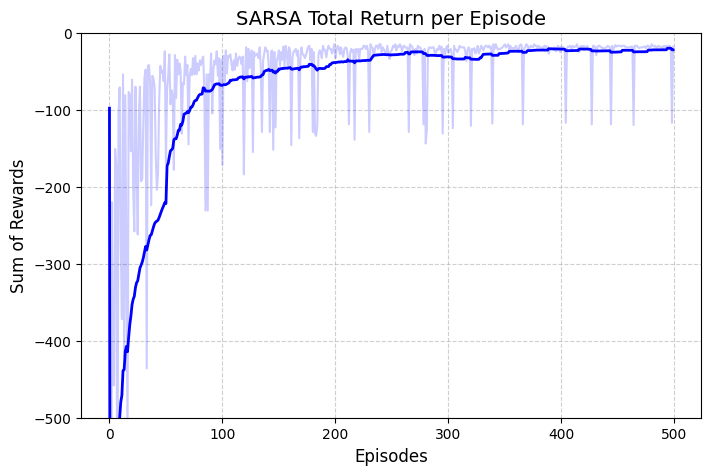

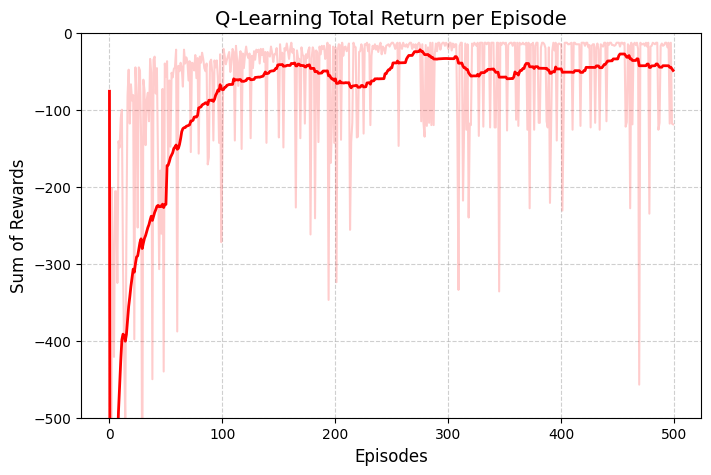

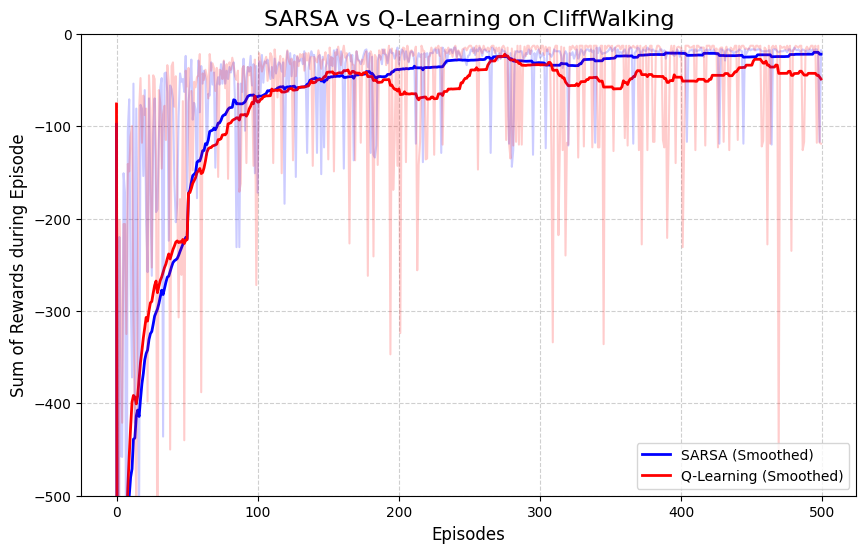

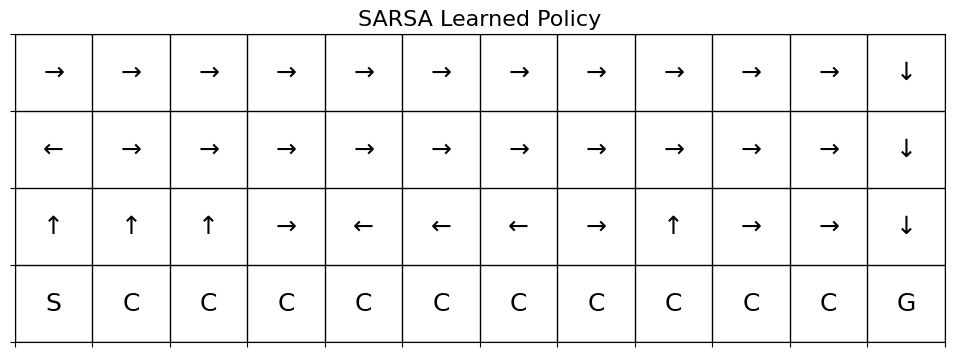

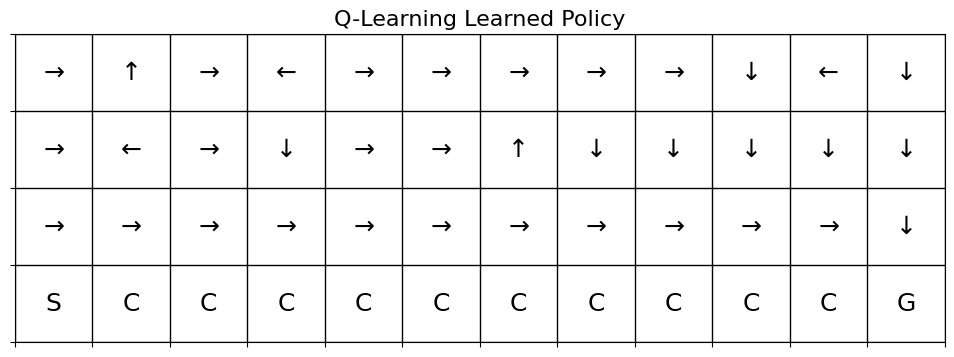

In [48]:
# Training & Comparing

# initialize the environment and parameter values.
env = gym.make('CliffWalking-v1')
episodes = 500
alpha = 0.1 #learning rate
gamma = 0.9 #discount factor
epsilon = 0.1 #greedy exploration

# training the models
print("Training SARSA")
Q_sarsa, returns_sarsa = run_sarsa(env, episodes, alpha, gamma, epsilon)

print("Training Q-Learning")
Q_qlearn, returns_qlearn = run_q_learning(env, episodes, alpha, gamma, epsilon)

# save the data
df_results = pd.DataFrame({
    'Episode': np.arange(1, episodes + 1),
    'SARSA_Return': returns_sarsa,
    'QLearning_Return': returns_qlearn
})
df_results.to_csv("RL_hw3_data/standard_training_returns.csv", index=False)
print("Training data saved to 'RL_hw3_data/standard_training_returns.csv'")

# plot curves
plt.figure(figsize=(8, 5))
plt.plot(smooth_curve(returns_sarsa), color='blue', linewidth=2)
plt.plot(returns_sarsa, color='blue', alpha=0.2)
plt.title('SARSA Total Return per Episode', fontsize=14)
plt.xlabel('Episodes', fontsize=12)
plt.ylabel('Sum of Rewards', fontsize=12)
plt.ylim(-500, 0)
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig("RL_hw3_data/sarsa_learning_curve.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(smooth_curve(returns_qlearn), color='red', linewidth=2)
plt.plot(returns_qlearn, color='red', alpha=0.2)
plt.title('Q-Learning Total Return per Episode', fontsize=14)
plt.xlabel('Episodes', fontsize=12)
plt.ylabel('Sum of Rewards', fontsize=12)
plt.ylim(-500, 0)
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig("RL_hw3_data/qlearning_curve.png", dpi=300)
plt.show()


plt.figure(figsize=(10, 6))
plt.plot(smooth_curve(returns_sarsa), label='SARSA (Smoothed)', color='blue', linewidth=2)
plt.plot(smooth_curve(returns_qlearn), label='Q-Learning (Smoothed)', color='red', linewidth=2)
# adding faded lines for raw data
plt.plot(returns_sarsa, color='blue', alpha=0.2)
plt.plot(returns_qlearn, color='red', alpha=0.2)
plt.title('SARSA vs Q-Learning on CliffWalking', fontsize=16)
plt.xlabel('Episodes', fontsize=12)
plt.ylabel('Sum of Rewards during Episode', fontsize=12)
plt.ylim(-500, 0)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig("RL_hw3_data/learning_curves_comparison.png", dpi=300)
plt.show()


# Visualize Policies
visualize_policy(Q_sarsa, "SARSA Learned Policy", "sarsa_policy")
visualize_policy(Q_qlearn, "Q-Learning Learned Policy", "qlearning_policy")

In [49]:
# # Training & Comparing

# # initialize the environment and parameter values.
# env = gym.make('CliffWalking-v1')
# episodes = 500
# alpha = 0.1 #learning rate
# gamma = 0.9 #discount factor
# epsilon = 0.1 #greedy exploration

# # training the models
# print("Training SARSA")
# Q_sarsa, returns_sarsa = run_sarsa(env, episodes, alpha, gamma, epsilon)

# print("Training Q-Learning")
# Q_qlearn, returns_qlearn = run_q_learning(env, episodes, alpha, gamma, epsilon)

# # save the data
# df_results = pd.DataFrame({
#     'Episode': np.arange(1, episodes + 1),
#     'SARSA_Return': returns_sarsa,
#     'QLearning_Return': returns_qlearn
# })
# df_results.to_csv("RL_hw3_data/standard_training_returns.csv", index=False)
# print("Training data saved to 'RL_hw3_data/standard_training_returns.csv'")

# # plot curves
# plt.figure(figsize=(10, 6))
# plt.plot(smooth_curve(returns_sarsa), label='SARSA (Smoothed)', color='blue', linewidth=2)
# plt.plot(smooth_curve(returns_qlearn), label='Q-Learning (Smoothed)', color='red', linewidth=2)
# # adding faded lines for raw data
# plt.plot(returns_sarsa, color='blue', alpha=0.2)
# plt.plot(returns_qlearn, color='red', alpha=0.2)
# plt.title('SARSA vs Q-Learning on CliffWalking', fontsize=16)
# plt.xlabel('Episodes', fontsize=12)
# plt.ylabel('Sum of Rewards during Episode', fontsize=12)
# plt.ylim(-500, 0)
# plt.legend(loc='lower right')
# plt.grid(True, linestyle='--', alpha=0.6)
# plt.savefig("RL_hw3_data/learning_curves_comparison.png", dpi=300)
# plt.show()

# # Visualize Policies
# visualize_policy(Q_sarsa, "SARSA Learned Policy", "sarsa_policy")
# visualize_policy(Q_qlearn, "Q-Learning Learned Policy", "qlearning_policy")

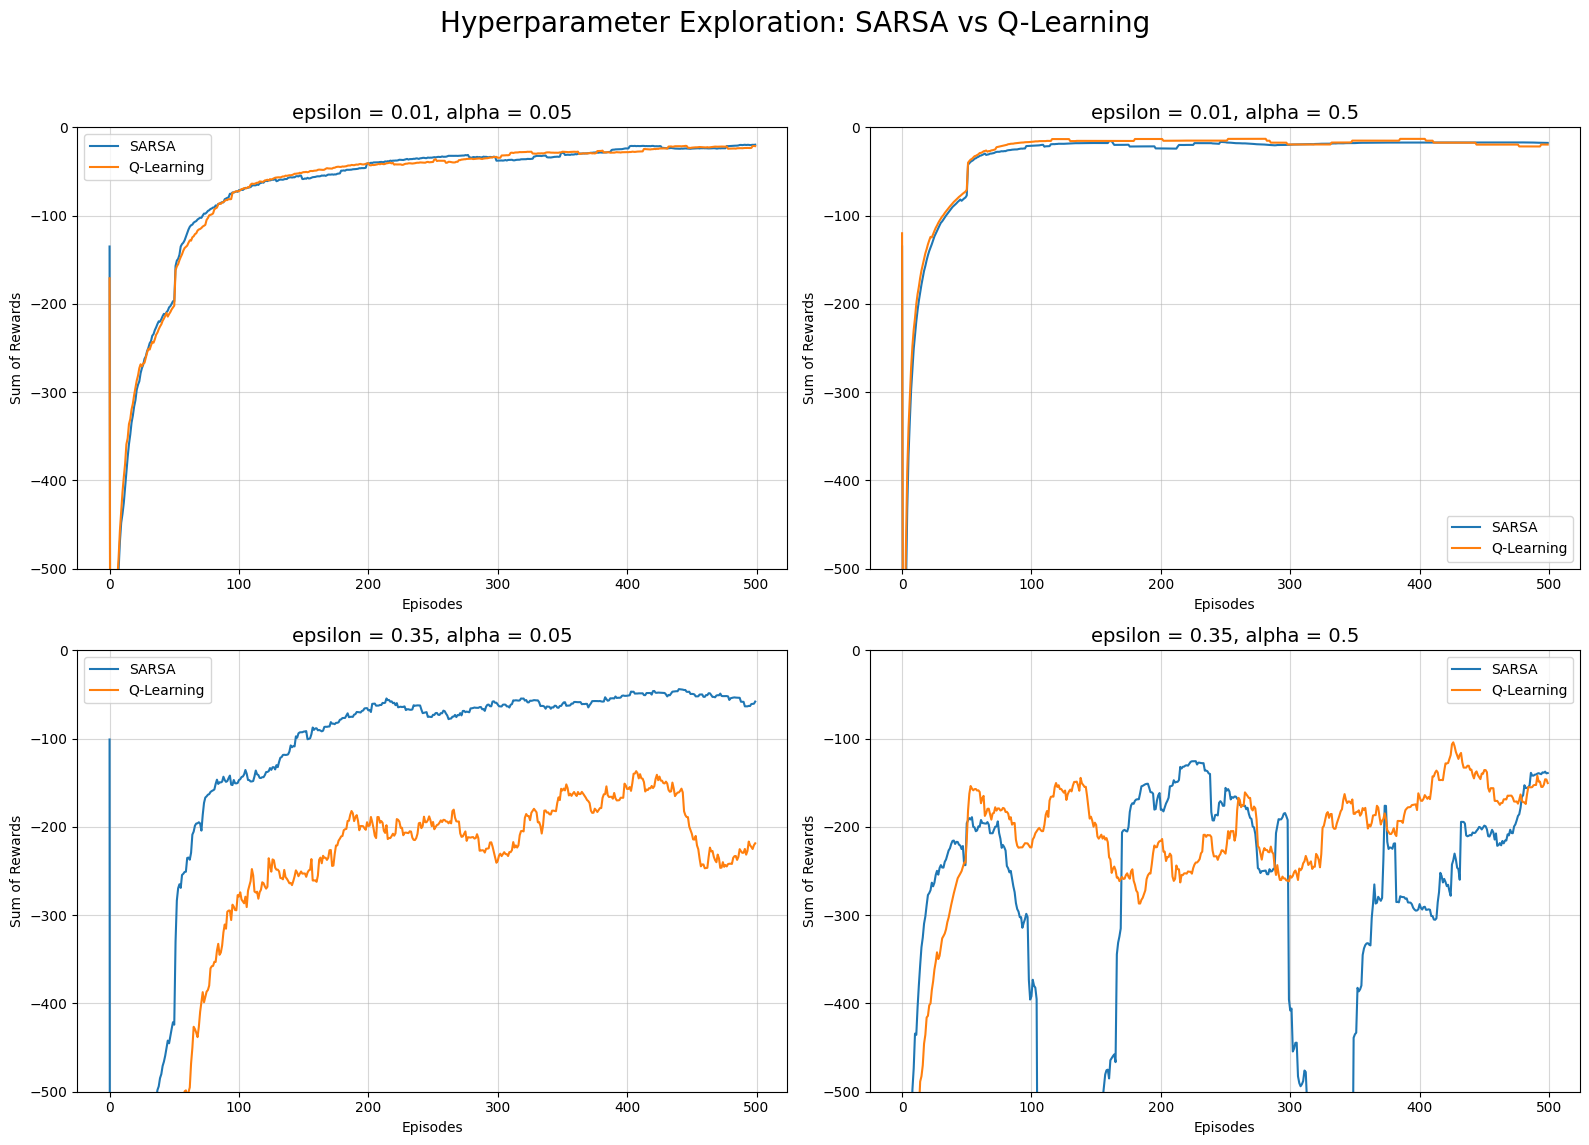

In [50]:
# Changing Hyperparameter values to assess how it effects the results.

# parameters to test
epsilons_to_test = [0.01, 0.35] # Very low vs High exploration
alphas_to_test = [0.05, 0.5]   # Small step vs Large step

# epsilons_to_test = [0.01, 0.2] # Very low vs High exploration
# alphas_to_test = [0.05, 0.3]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Hyperparameter Exploration: SARSA vs Q-Learning", fontsize=20)

plot_idx = 0

for eps in epsilons_to_test:
    for a in alphas_to_test:
        row = plot_idx // 2
        col = plot_idx % 2
        ax = axes[row, col]

        _, returns_sarsa_exp = run_sarsa(env, episodes=500, alpha=a, gamma=0.9, epsilon=eps)
        _, returns_qlearn_exp = run_q_learning(env, episodes=500, alpha=a, gamma=0.9, epsilon=eps)

        ax.plot(smooth_curve(returns_sarsa_exp), label='SARSA')
        ax.plot(smooth_curve(returns_qlearn_exp), label='Q-Learning')
        ax.set_title(f"epsilon = {eps}, alpha = {a}", fontsize=14)
        ax.set_xlabel("Episodes")
        ax.set_ylabel("Sum of Rewards")
        ax.set_ylim(-500, 0)
        ax.grid(True, alpha=0.5)
        ax.legend()

        plot_idx += 1

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("RL_hw3_data/hyperparameter_exploration.png", dpi=300)
plt.show()